# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [9]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


### Load LOB data

In [10]:
dataset = pd.read_parquet('./Data/LOBSTER/MSFT.parquet')
dataset = dataset.astype(float)
dataset = dataset.head(200000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,308600.0,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,308600.0,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,308600.0,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,308600.0,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,308600.0,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,307400.0,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0
199996,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,307400.0,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0
199997,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,307400.0,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0
199998,308300.0,25520.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,307400.0,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0


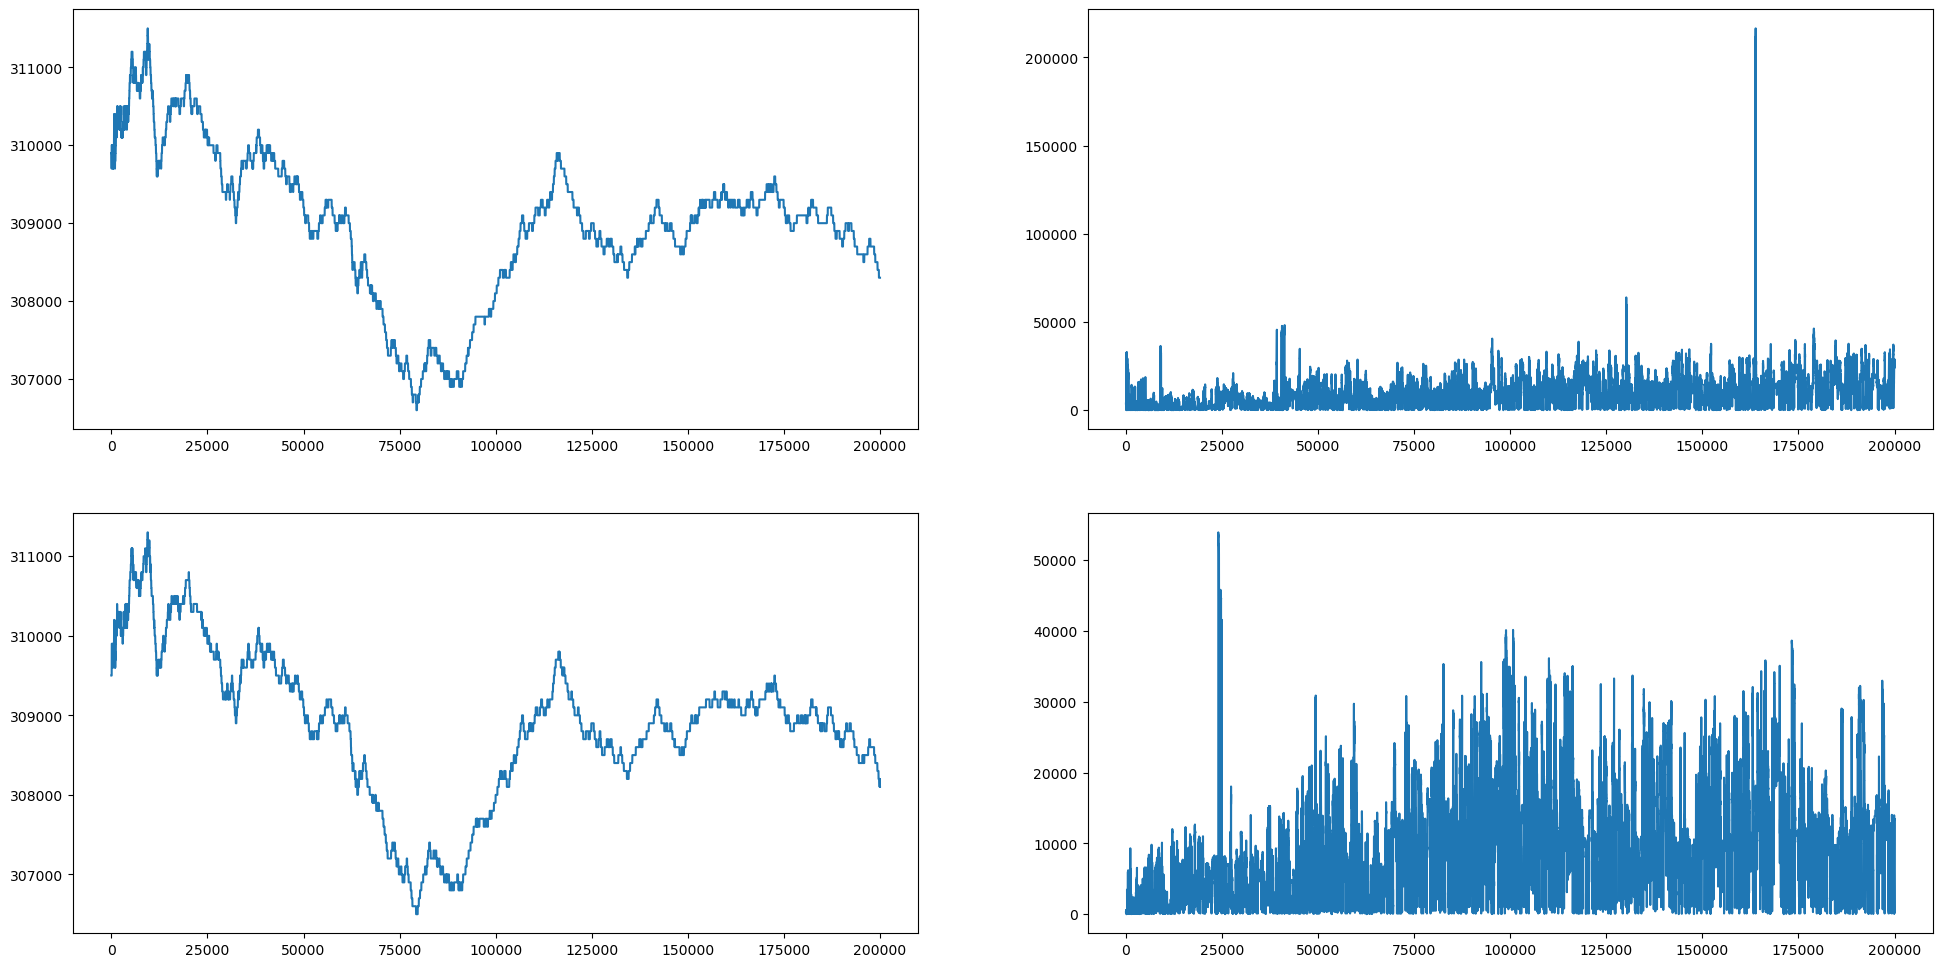

In [11]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

### Create the effective time-series dataset, and the batch-iterators to process tensors

The procedure is the sliding window procedure

In [12]:
target_col = 'P_Ask_1'
target_cols = []
shifts = [ 1 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_1
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309900.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309900.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309900.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309900.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309900.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199994,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308300.0
199995,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308300.0
199996,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308300.0
199997,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308300.0


In [13]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
#scaler = preprocessing.StandardScaler()
#scaler.fit(dataset_train)

#dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
#dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
#dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

means = dataset_train.mean(axis=0)
stds = dataset_train.std(axis=0)

means[-len(target_cols):] = means[target_cols]
stds[-len(target_cols):] = stds[target_cols]

dataset_train = ( dataset_train - means ) / stds
dataset_val = ( dataset_val - means ) / stds
dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_1
0,0.843166,-0.781947,0.606174,-1.282663,1.293094,-1.551817,0.515731,-1.086857,1.293040,-1.583158,...,-1.527192,1.383036,-0.767996,0.425203,-1.364111,1.383000,-0.712045,0.425203,-0.872293,0.843174
1,0.843166,-0.781947,0.606174,-1.282663,1.293094,-1.538432,0.515731,-1.086857,1.293040,-1.583158,...,-1.527192,1.383036,-0.767996,0.425203,-1.364111,1.383000,-0.712045,0.425203,-0.872293,0.843174
2,0.843166,-0.781947,0.606174,-1.282663,1.203068,-1.551817,0.515731,-1.086857,1.203017,-1.569831,...,-1.527192,1.202991,-0.272672,0.425203,-1.364111,1.292979,-0.712045,0.425203,-0.872293,0.843174
3,0.843166,-0.781947,0.606174,-1.282663,1.203068,-1.551817,0.515731,-1.086857,1.203017,-1.556504,...,-1.527192,1.202991,-0.272672,0.425203,-1.364111,1.292979,-0.712045,0.425203,-0.872293,0.843174
4,0.843166,-0.781947,0.606174,-1.282663,1.203068,-1.551817,0.515731,-1.086857,1.203017,-1.556504,...,-1.527192,1.202991,-0.272672,0.425203,-1.364111,1.292979,-0.712045,0.425203,-0.872293,0.843174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139994,0.032841,-0.370605,0.062795,1.474029,0.032733,1.152577,0.062881,0.540874,0.032710,0.330694,...,1.769055,0.032697,-0.160098,0.062915,1.607562,0.032684,-0.357183,0.062915,1.534820,0.032847
139995,0.032841,-0.370605,0.062795,1.474029,0.032733,1.152577,0.062881,0.540874,0.032710,0.330694,...,1.746768,0.032697,-0.160098,0.062915,1.607562,0.032684,-0.357183,0.062915,1.534820,0.032847
139996,0.032841,-0.516886,0.062795,1.474029,0.032733,1.152577,0.062881,0.540874,0.032710,0.330694,...,1.746768,0.032697,-0.160098,0.062915,1.607562,0.032684,-0.357183,0.062915,1.534820,0.032847
139997,0.032841,-0.516886,0.062795,1.474029,0.032733,1.152577,0.062881,0.540874,0.032710,0.330694,...,1.601011,0.032697,-0.160098,0.062915,1.607562,0.032684,-0.357183,0.062915,1.534820,0.032847


In [14]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = batch_size,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 139800 samples
Test dataset: 29802 samples


## Train the models

### Baisc LSTM

In [15]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [18]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
epochs = 3
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'LSTM1',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/3 [00:00<?, ?it/s]

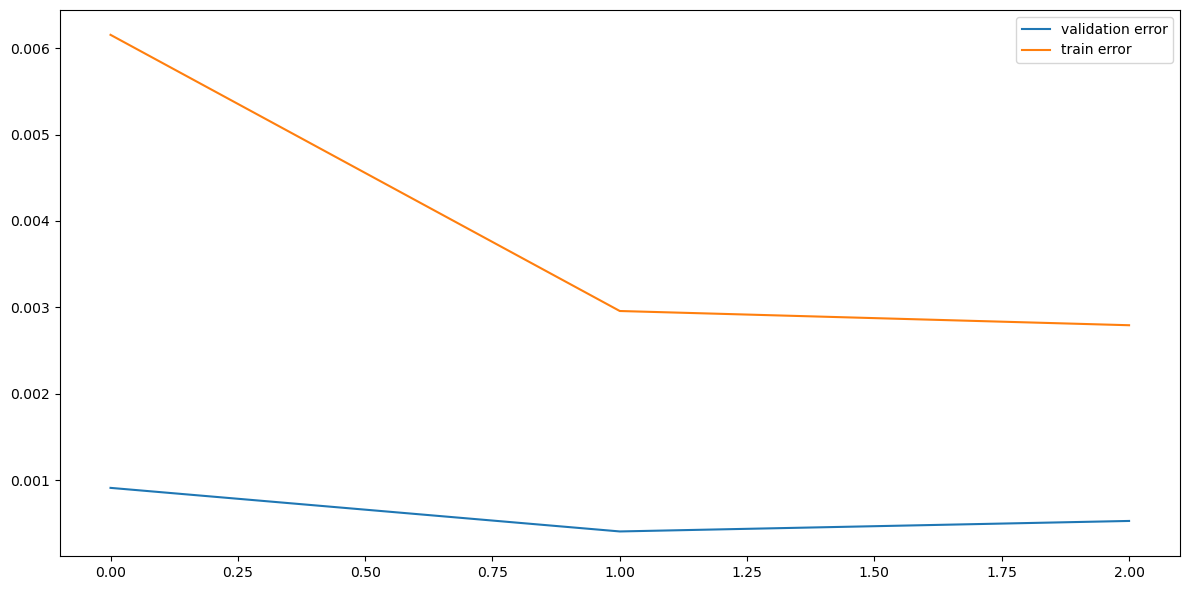

In [19]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [20]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
for i in range(y_train.shape[1]):
    fig = go.Figure()
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy")
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green")
    fig.update_layout(title = f"Horizon {shifts[i]}", xaxis_title = "Time", yaxis_title = "Price")
    fig.show()

### LSTM2

In [21]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [22]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM2(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
epochs = 3
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'LSTM2',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/3 [00:00<?, ?it/s]

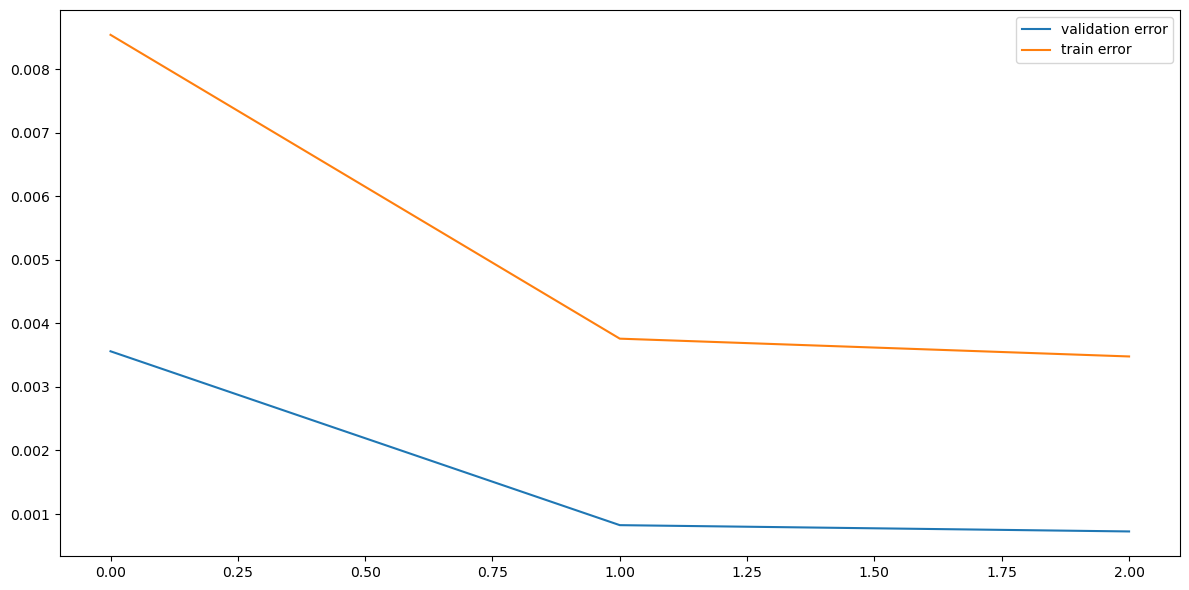

In [23]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [24]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
for i in range(y_train.shape[1]):
    fig = go.Figure()
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy")
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green")
    fig.update_layout(title = f"Horizon {shifts[i]}", xaxis_title = "Time", yaxis_title = "Price")
    fig.show()

### LSTM with Attention mechanism

In [25]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [26]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'encoder_hidden_size': 64,
    'encoder_layers': 2,
    'decoder_hidden_size': 64,
    'decoder_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTMWithAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
epochs = 4
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'LSTMWithAttention',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/4 [00:00<?, ?it/s]

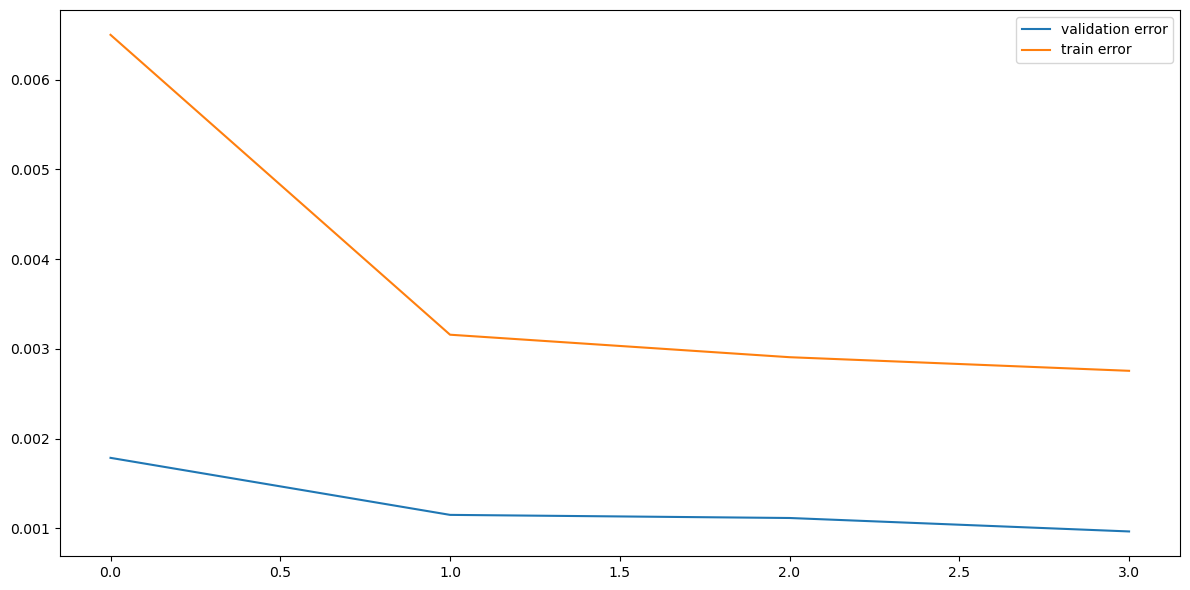

In [27]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [28]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
for i in range(y_train.shape[1]):
    fig = go.Figure()
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy")
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green")
    fig.update_layout(title = f"Horizon {shifts[i]}", xaxis_title = "Time", yaxis_title = "Price")
    fig.show()

### LobCNN

In [ ]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [ ]:
# Create the model
params = {
    "lookback_period": 100,
    "inner_convolutional_layers": 2,
    "smoothing_percentage": 0.06,
    "convolution_channels": 32,
    "inception_channels": 64,
    "lstm_layers": 2,
    "output_size": y_train.shape[1],
    "regression": True
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
epochs = 3
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'LobCNN',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    trainloader = dataloader_train,
    valloader = dataloader_val,
    epochs = epochs,
    save = False,
    device = device
)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1


/orfeo/cephfs/home/dssc/gpintus/Jupyter/jupyter/lib64/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning:

Attempt to open cnn_infer failed: handle=0 error: libcudnn_cnn_infer.so.8: cannot open shared object file: No such file or directory (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:81.)



Duration of training epoch 1: 3.861999750137329, seconds
Epoch 1/3, Train Loss: 0.05979688, Val Loss:  0.07990325, 
[=================---------------------------------] 33.3%  starting epoch 2
Duration of training epoch 2: 3.604262113571167, seconds
Epoch 2/3, Train Loss: 0.02663826, Val Loss:  0.43656179, 
[=================================-----------------] 66.7%  starting epoch 3
Duration of training epoch 3: 3.61751389503479, seconds
Epoch 3/3, Train Loss: 0.01376161, Val Loss:  0.11768306, 


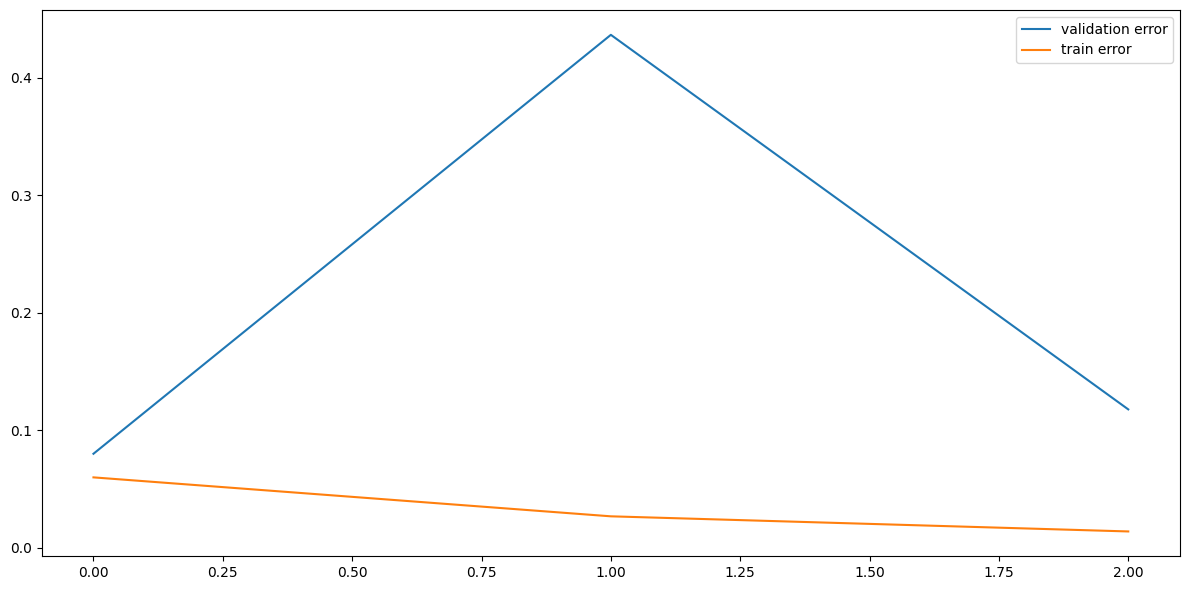

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

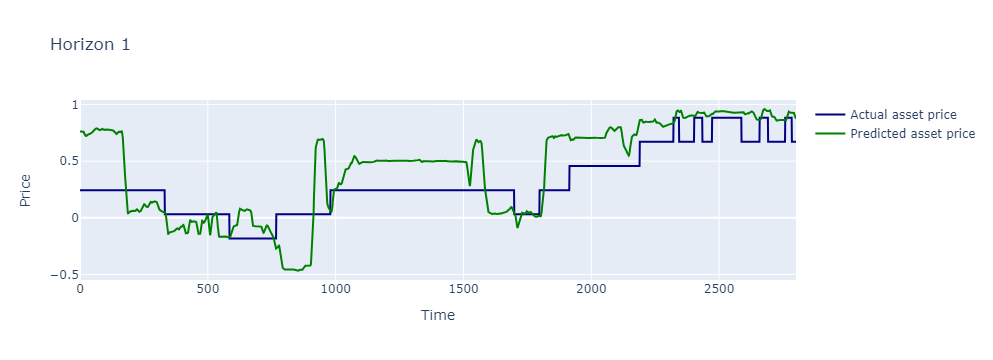

In [ ]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
for i in range(y_train.shape[1]):
    fig = go.Figure()
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy")
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green")
    fig.update_layout(title = f"Horizon {shifts[i]}", xaxis_title = "Time", yaxis_title = "Price")
    fig.show()

### Astice

In [ ]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [ ]:
# Create the model
params = {
    "input_size": X_train.shape[1],
    "output_size": y_train.shape[1],
    "hidden_size": 64,
    "lstm_size": 64,
    "lstm_layers": 2,
    "smooth_conv_channels": 16
}

model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
epochs = 3
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'Astice',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    trainloader = dataloader_train,
    valloader = dataloader_val,
    epochs = epochs,
    save = False,
    device = device
)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1
Duration of training epoch 1: 1.4837884902954102, seconds
Epoch 1/3, Train Loss: 0.02647211, Val Loss:  0.00881029, 
[=================---------------------------------] 33.3%  starting epoch 2
Duration of training epoch 2: 1.4801855087280273, seconds
Epoch 2/3, Train Loss: 0.00188517, Val Loss:  0.00130475, 
[=================================-----------------] 66.7%  starting epoch 3
Duration of training epoch 3: 1.4762682914733887, seconds
Epoch 3/3, Train Loss: 0.00183103, Val Loss:  0.00266448, 
